# Estimating Electricity Outage Duration in Rwanda

## 1. Problem & Data Context

**Use case:** Electricity providers in Rwanda can use this model to estimate how long outages last for a grid-connected household in a typical week, so they can spot households at risk of long interruptions and prioritise maintenance.

**Dataset:** 2022 Rwanda Multi-Tier Framework (MTF) Energy Survey, `SECTION_C1.csv`: 5,706 households (one row each) and 280 columns on grid access, outages, and household and location details.

**Target:** `outage_duration_minutes`, the total outage time in a typical week, in minutes which is capped at 300.

## 2. Data Loading and Cleaning

First start by importing all the libraries you will need.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.base import clone

In [2]:
data_file = Path("data/SECTION_C1.csv")

# the best model and its training data will be saved here
api_folder = Path("../API")

### 2.1 Load the data and check what each row represents

In [3]:
# load the data
df = pd.read_csv('./data/SECTION_C1.csv', low_memory=False)

In [4]:
print("Rows, columns:", df.shape)

Rows, columns: (5706, 280)


Find out what each row represents in the data.

In [5]:
# checking to see what each row represents
print("Total rows:", len(df))
print("Unique household IDs:", df['hhid'].nunique())

Total rows: 5706
Unique household IDs: 5706


Each row is one household (every `hhid` is unique). Column `C002` shows grid connection: `1` = connected to the national grid, `0` = not connected. I keep only grid-connected households, and only those that give a unit (hours or minutes) for their outage duration, because without the unit the duration can't be converted.

In [6]:
# houses connected to the grid
connected_to_grid = df[df['C002'] == 1]
print("Number of households connected to the grid:", len(connected_to_grid))
print("Of these,", (connected_to_grid["C031B"] == 111).sum(), "reported no outages.")

Number of households connected to the grid: 2649
Of these, 570 reported no outages.


In [7]:
outage_households = connected_to_grid[connected_to_grid["C032B_UNITY"].notna()].copy()
print("Grid connected households with a duration unit:", len(outage_households))

Grid connected households with a duration unit: 1782


2,649 households are connected to the grid, and 1,782 of them give a duration unit. These 1,782 households are the modelling data.

### 2.2 Special survey codes
The survey uses codes instead of blanks for some answers:
- **888** = "don't know", treated as missing
- **111** = "none", kept as its own category
- **555** = "other", kept as its own category
- **999** = "missing", treated as missing

### 2.3 Create the Target from C032B and C032B_UNITY
I will use the `C032B` which is the raw duration value and `C032B_UNITY` which is the duration unit to create the target column `outage_duration_minutes`. I will have to convert the rows whose units are in hours to minutes.
First I need to find out how many rows have a particular unit.

In [8]:
print(outage_households.groupby("C032B_UNITY")["C032B"].describe())

              count       mean        std  min  25%   50%   75%    max
C032B_UNITY                                                           
1.0           468.0   7.029915   8.293541  5.0  5.0   5.0   5.0  120.0
2.0          1314.0  27.378234  28.516147  5.0  5.0  20.0  30.0  120.0


In [9]:
Hour_rows = outage_households[(outage_households['C002'] == 1) & (outage_households['C032B_UNITY'] == 1)]
print(Hour_rows['C032B'].value_counts(dropna=False))

C032B
5.0      415
10.0      18
25.0      13
15.0       6
20.0       5
40.0       4
30.0       4
60.0       2
120.0      1
Name: count, dtype: int64


468 households answer in hours and 1,314 in minutes. Of the hour answers, 415 are 5 hours and 53 are longer (up to 120 hours = 7,200 minutes). Those 53 answers would dominate the squared error, so I convert hours to minutes and cap the target at 300 minutes (5 hours).

In [10]:
target_col = "outage_duration_minutes"

outage_households[target_col] = np.where(
    outage_households["C032B_UNITY"] == 1,
    outage_households["C032B"] * 60,
    outage_households["C032B"]
)
outage_households[target_col] = outage_households[target_col].clip(upper=300)

## 3. Explore the data

### 3.1 Data Visualizations

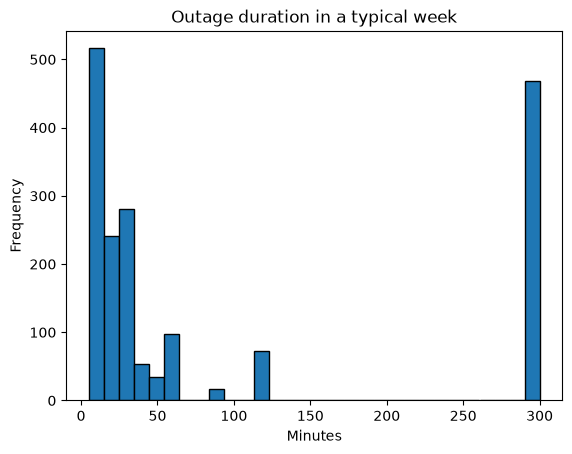

In [11]:
outage_households[target_col].plot.hist(bins=30, edgecolor="black", title="Outage duration in a typical week")
plt.xlabel("Minutes")
plt.show()

The bulk is at the left side of the histogram. It indicates that most of the households have the smaller values that is why the tallest bar is at the left. At 300, the spike pull the mean above the median. The empty gap between 120 and 290 shows that no values fall here because the raw values of the minutes group range from 5 to 120 so they are not converted and 120 is the largest that group can produce. the hours group also has vlaues from 5 to 120 and the lowest it can produce when multiplied by 60 is 300. this is why there is the empty space. the spike is made of the 415 households that recorded 5 hours and the 53 that recorded more than 5 hours but I capped. I capped the values at 300 minutes so that 53 extreme answers wouldn't dominate the MSE.
Most households report short outages, so the bars are tallest on the left, with a spike at 300 minutes made up of the hour answers (5 hours, plus the 53 longer answers I capped). The gap between 120 and 300 exists because minute answers go up to 120, while the smallest hour answer converts to 300. Because of this skew and the cap, I judge every model against a simple "predict the mean" baseline, not just against each other.

### Feature Selection
I chose these feature to investigate based on their relevancee to electricity outages. 

The table below lists all variables from `SECTION_C1.csv` that were excluded from the predictor matrix (`X`) when modeling typical-week electricity outage duration on the national grid, along with the reason for each exclusion.

| Variables | Reason Excluded |
| :--- | :--- |
| `C032B`, `C032B_UNITY`, `C032b_unity` | **Direct Target & Unit Inputs:** These columns directly construct the target variable (`y` typical-week outage duration in minutes) and cannot be used as predictors. |
| `C029B`, `C030B` | **Mathematical Complements (Target Leakage):** Daily/nightly and evening hours of electricity availability in typical months are direct complements of outage duration, leaking the target outcome into `X`. |
| `C027A`–`C027M`, `C028A`, `C029A`, `C030A`, `C031A`, `C032A`, `C032A_UNITY`, `C032a_unity` | **Worst-Month / Worst-Week Metrics:** Measure worst-month or worst-week outages and availability rather than typical-week behavior, blurring the modeling objective and introducing overlap with the target. |
| `C033`, `C034`, `C036`, `C037_FIRST`, `C037_SECOND` | **Post-Outage Reactions & Consequences:** Capture household responses or impacts after outages occur (backup lighting/appliances, voltage-damaged appliances, and most serious grid problems) rather than clean pre-outcome predictors. |
| `C041`, `C042`, `C043`, `C044`, `C045`, `C046`, `C047`, `C048`, `C049`, `C050`, `C051`, `C052`, `C053`, `C054`, `C055`, `C056`, `C057`, `C058`, `C059`, `C060`, `C061`, `C062`, `C063`, `C064`, `C065`, `C066`, `C067`, `C068A`–`C068M`, `C069C`–`C073D`, `C073C_UNITY`, `C073C_unity`, `C073D_UNITY`, `C073D_unity`, `C074`, `C075`, `C076`, `C077`, `C078_FIRST`, `C078_SECOND`, `C079`, `C080`, `C081` | **Mini-Grid Module:** Belong to the mini-grid survey section (connection reasons, tariffs, mini-grid outages, backup sources, and mini-grid issues), which applies to a different supply regime than the national grid. |
| `C082`, `C083`, `C084`, `C085`, `C086A`–`C086M`, `C087`, `C088A`–`C088E`, `C089`, `C090`, `C091`, `C092`, `C093`, `C094`, `C095`, `C096`, `C097`, `C098`, `C099`, `C100`, `C100_UNITY`, `C100_unity`, `C101`, `C102_FIRST`, `C102_SECOND`, `C103`, `C104`, `C105` | **Generator Module (Equipment-Specific / Out of Scope):** Describe generator ownership, fuel usage, maintenance, and generator outages rather than national-grid reliability. |
| `C106`, `C107A`–`C107N`, `C108A`–`C108D`, `C109`, `C110`, `C111`, `C112`, `C113`, `C114`, `C115`, `C116`, `C117`, `C118`, `C119`, `C120`, `C121`, `C122_FIRST`, `C122_SECOND`, `C123`, `C124`, `C125`, `C126` | **Rechargeable Batteries & Inverters Module:** Cover battery/inverter capacity, charging costs, and disposal—storage equipment details unrelated to national-grid outage duration. |
| `C127`, `C152`, `C153`, `C154`, `C155`, `C156`, `C157`, `C158`, `C159`, `C160`, `C161`, `C162`, `C163`, `C164_1`–`C164_8`, `C165`, `C166`, `C167`, `C168`, `C169`, `C170_1`–`C170_8` | **Solar Devices Module:** Capture standalone solar device payments, usage shifts, and desired appliances rather than national-grid infrastructure or fault duration. |
| `C172`, `C173`, `C174`, `C175`, `C176`, `C177` | **Mobile Phones & Internet Access:** Track phone ownership, external phone charging, and internet access, which add noise without directly explaining grid outage duration. |
| `PROVINCE` | **Redundant Geography:** Fully nested within `DISTRICT`; keeping both introduces redundant encoding and collinearity. |
| `Cluster`, `PSU`, `HI05`, `HH_Quest_Number`, `C001`, `hhid`, `camp`, `ref_weight`, all `*_OTHER` / `*_Other` fields | **Identifiers, Survey Metadata & Free-Text Fields:** Administrative/sampling IDs and unstandardized open-ended text fields do not generalize as predictive features. |
| `HH_WT` | **Survey Sampling Weight:** Represents household sampling weight for population-level estimation; should only be passed as `sample_weight` if weighted modeling is used, never as a column in `X`. |

In [12]:
candidate_cols = [
    "C031B", "C006", "DISTRICT", "HI04", "TYPEHH",
    "C008", "C012", "C013", "C014", "C015", "C016",
    "C018", "C019", "C026", "C028B", "C035", "C038", "C171"
]

special_codes = [111, 888, 555, 999]
special_code_counts = pd.DataFrame({
    code: (outage_households[candidate_cols] == code).sum() for code in special_codes
})
special_code_counts["total"] = special_code_counts.sum(axis=1)
print(special_code_counts)

          111  888  555   999  total
C031B       0    0    0     0      0
C006        0    0    0     0      0
DISTRICT    0    0    0     0      0
HI04        0    0    0     0      0
TYPEHH      0    0    0     0      0
C008        0    0    0     0      0
C012       29    0   24     0     53
C013        0    0   83     0     83
C014        0    0    0     0      0
C015        0    0    0     0      0
C016        0    0    0     0      0
C018       30    0   52     0     82
C019        0    0   53     0     53
C026        0    0    0     0      0
C028B       0    0    0     0      0
C035      201    0    0  1059   1260
C038        0    2    0     0      2
C171        0    0    0     0      0


Some of these columns could have the special codes we talked about earlier. Seeing the number of codes I have to deal with will help me decide whether I want to keep that particular column as a feature or not.

In [13]:
# Share of the most common values, to check whether a column barely varies
for column in ["C013", "C014", "C015", "C016", "C171"]:
    share_of_each_value = outage_households[column].value_counts(normalize=True, dropna=False)
    print(column, share_of_each_value.round(3).head(3).to_dict())

C013 {3.0: 0.793, 2.0: 0.088, 555.0: 0.047}
C014 {1.0: 0.944, 0.0: 0.04, nan: 0.016}
C015 {1.0: 0.937, nan: 0.056, 0.0: 0.007}
C016 {0.0: 0.838, 1.0: 0.162}
C171 {1: 1.0}


### 3.2 Columns dropped from the candidates
- **C035** (days to fix a connection problem): 1,260 of 1,782 rows are special codes, so it is mostly unusable.
- **C171** (source mostly used): every household has the same value (100% = 1), so it carries no information.
- **C014** (has an electric meter): 94% of households have the same answer, so it barely varies.
- **C015** (prepaid meter): 94% of households have the same answer, so it barely varies.
- **C013** (payment frequency): 79% share one answer, and it describes billing rather than supply; payment and billing are already covered by C019 and C018.
- **C016** (shares a meter): 84% share one answer, and meter sharing is about billing, not how long the supply is cut.

In [14]:
numeric_features = ["C031B", "C006"]  # counts: outages per week, years connected
categorical_features = [
    "DISTRICT", "HI04", "TYPEHH", "C008", "C012",
    "C018", "C019", "C026", "C028B", "C038",
]
feature_columns = numeric_features + categorical_features
print(len(feature_columns), "features")

12 features


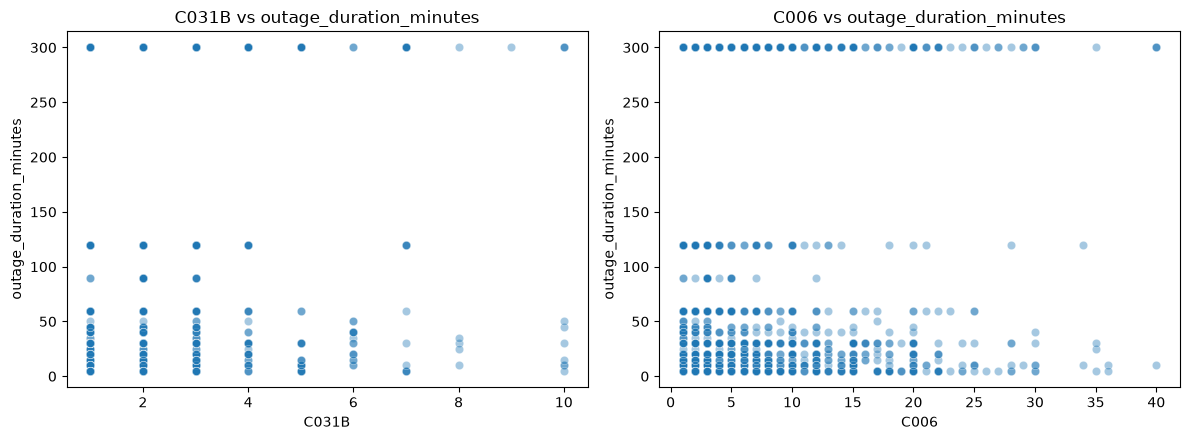

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for axis, column in zip(axes, numeric_features):
    sns.scatterplot(data=outage_households, x=column, y=target_col, alpha=0.4, ax=axis)
    axis.set_title(f"{column} vs {target_col}")

plt.tight_layout()
plt.show()

The scatter plots show that both the numeric columns are do not show a clear linear trend. The points stack at discrete values and spread across the full range of durations. I still decided to keep both, because a weak linear pattern doesn't mean there is no non-linear one.

## 4. Data Preparation
I am using an 80/20 split for the data so 80% will be used to train and 20% of the data will be used to test. I replaced the `888` values in the `C038` columns since it is the only column in our target that has the value `888`.

In [16]:
X = outage_households[feature_columns].copy()
y = outage_households[target_col]

X["C038"] = X["C038"].replace(888, np.nan)   # 888 = "don't know" is treated as missing

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (1425, 12) Test: (357, 12)


In [17]:
preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features), # fill missing values with the median.
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")), # fill missing values with the most frequent one
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), categorical_features),
])
scaler = StandardScaler()

# Fit on the training set only, then apply the same transformation to the test set
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)
X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

encoded_feature_names = preprocessor.get_feature_names_out()
print("Columns after one-hot encoding:", X_train_scaled.shape[1])

Columns after one-hot encoding: 67


cat__DISTRICT_37.0    0.115
cat__C028B_1.0        0.107
cat__C028B_0.0       -0.107
cat__C019_2.0         0.102
cat__HI04_1.0        -0.086
cat__HI04_2.0         0.086
cat__DISTRICT_36.0    0.084
cat__DISTRICT_41.0    0.083
cat__DISTRICT_22.0    0.083
cat__DISTRICT_53.0   -0.076
Name: target, dtype: float64
Most correlated feature: cat__DISTRICT_37.0


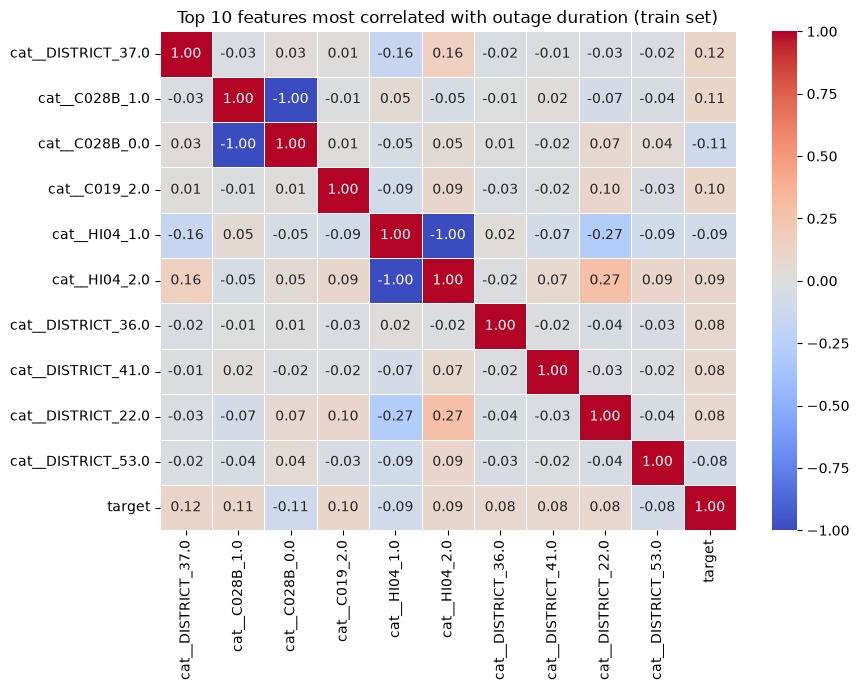

In [18]:
train_table = pd.DataFrame(X_train_scaled, columns=encoded_feature_names)
train_table["target"] = y_train.values

correlation_with_target = train_table.corr()["target"].drop("target")
top_10_features = correlation_with_target.abs().sort_values(ascending=False).head(10).index
most_correlated_feature = top_10_features[0]  # used again for the scatter plots

print(correlation_with_target[top_10_features].round(3))
print("Most correlated feature:", most_correlated_feature)

plt.figure(figsize=(9, 7))
sns.heatmap(train_table[list(top_10_features) + ["target"]].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, center=0, linewidths=0.5)
plt.title("Top 10 features most correlated with outage duration (train set)")
plt.tight_layout()
plt.show()

The heatmap shows the 10 encoded features most correlated with outage duration on the training set. Every correlation is weak (the strongest is about 0.12, for district 37), so no single feature explains duration on its own. Because of this I kept the full set of 12 features instead of trimming to the top few, and I expect the linear models to do only modestly better than predicting the mean.

DISTRICT    0.318
C006        0.188
C018        0.115
C012        0.075
C031B       0.072
C019        0.067
C026        0.042
HI04        0.040
C038        0.027
C028B       0.024
C008        0.018
TYPEHH      0.014
dtype: float64


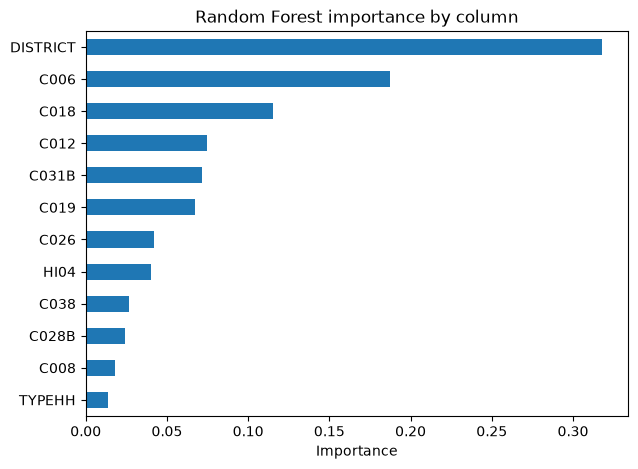

In [19]:
importance_forest = RandomForestRegressor(n_estimators=200, random_state=42)
importance_forest.fit(X_train_scaled, y_train)
importance = pd.Series(importance_forest.feature_importances_, index=encoded_feature_names)


def original_column(encoded_name):
    """Turn 'cat__DISTRICT_37.0' back into 'DISTRICT' (and 'num__C006' into 'C006')."""
    name = encoded_name.split("__", 1)[1]
    return next((c for c in categorical_features if name.startswith(c + "_")), name)


importance_by_column = importance.groupby(importance.index.map(original_column)).sum()
importance_by_column = importance_by_column.sort_values(ascending=False)
print(importance_by_column.round(3))

importance_by_column[::-1].plot.barh(figsize=(7, 5), title="Random Forest importance by column")
plt.xlabel("Importance")
plt.show()

Random Forest importance, summed back to the original columns. It ranks DISTRICT first (0.32), then C006 (0.19) and C018 (0.12). C006 has almost no linear correlation with the target (-0.04) but ranks second in importance, which points to a non-linear relationship that tree models can capture and linear regression cannot. DISTRICT’s score is likely inflated because it has many categories, so I treat this ranking as a guide.

## 5. Model training and comparison
### 5.1 Helper function
One function fits any model and returns its train and test MSE, so all four models are evaluated the same way on the same test set.

In [20]:
def train_and_score(model):
    """Fit one model on the training data and return (train MSE, test MSE)."""
    model.fit(X_train_scaled, y_train)
    train_mse = mean_squared_error(y_train, model.predict(X_train_scaled))
    test_mse = mean_squared_error(y_test, model.predict(X_test_scaled))
    return train_mse, test_mse

### 5.2 Baseline: all four models with default settings

In [21]:
baseline_models = {
    "SGD": SGDRegressor(random_state=42),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
}

baseline_scores = {name: train_and_score(model) for name, model in baseline_models.items()}
print(pd.DataFrame(baseline_scores, index=["Train MSE", "Test MSE"]).T.round(1))

                   Train MSE  Test MSE
SGD                  13149.8   15083.3
Linear Regression    13121.7   15054.7
Decision Tree          368.0   21924.9
Random Forest         2262.4   13521.8


### 5.3 Tune SGDRegressor
I try different learning rates (eta0), regularization strengths (alpha) and numbers of epochs. Each setting is scored on a validation split taken from the training data, so the test set is never used for tuning.

In [22]:
# Tune on a validation split taken from the training set, so the test set stays unseen
X_tune, X_validation, y_tune, y_validation = train_test_split(
    X_train_scaled, y_train, test_size=0.2, random_state=42
)

sgd_results = []
for learning_rate in [1e-5, 1e-4, 1e-3]:
    for regularization in [0.01, 0.1, 1, 10]:
        for epochs in [50, 200, 500]:
            sgd = SGDRegressor(learning_rate="constant", eta0=learning_rate, alpha=regularization,
                            max_iter=epochs, tol=None, random_state=42)
            sgd.fit(X_tune, y_tune)
            sgd_results.append({
                "learning_rate": learning_rate,
                "alpha": regularization,
                "epochs": epochs,
                "train_mse": mean_squared_error(y_tune, sgd.predict(X_tune)),
                "validation_mse": mean_squared_error(y_validation, sgd.predict(X_validation)),
            })

sgd_results = pd.DataFrame(sgd_results).sort_values("validation_mse")
print(sgd_results.head(10).round({"train_mse": 1, "validation_mse": 1}).to_string(index=False))

print("Validation baseline (predict the mean):",
    round(mean_squared_error(y_validation, np.full(len(y_validation), y_tune.mean())), 1))

best_sgd = sgd_results.iloc[0]
print("Best SGD settings:", best_sgd[["learning_rate", "alpha", "epochs"]].to_dict())

 learning_rate  alpha  epochs  train_mse  validation_mse
       0.00001    1.0     200    13718.1         13120.4
       0.00001    1.0     500    13604.9         13246.9
       0.00010    1.0      50    13602.7         13248.1
       0.00010    1.0     200    13603.6         13255.3
       0.00010    1.0     500    13603.3         13256.0
       0.00001   10.0     200    15090.4         13312.6
       0.00100    1.0     200    13672.8         13361.7
       0.00100    1.0     500    13687.7         13375.3
       0.00001   10.0     500    14983.1         13472.4
       0.00010   10.0     200    14986.5         13478.3
Validation baseline (predict the mean): 13678.2
Best SGD settings: {'learning_rate': 1e-05, 'alpha': 1.0, 'epochs': 200.0}


### 5.4 Final models
SGD uses the tuned settings from above and Linear Regression has no hyperparameters. The Decision Tree and Random Forest keep scikit-learn's default settings.

In [23]:
final_models = {
    "SGD": SGDRegressor(learning_rate="constant", eta0=best_sgd["learning_rate"],
                        alpha=best_sgd["alpha"], max_iter=int(best_sgd["epochs"]),
                        tol=None, random_state=42),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
}

### 5.5 Comparision of all four models

In [24]:
final_scores = {name: train_and_score(model) for name, model in final_models.items()}
comparison_table = pd.DataFrame(final_scores, index=["Train MSE", "Test MSE"]).T

# Reference: always predicting the training mean
mean_prediction_train = np.full(len(y_train), y_train.mean())
mean_prediction_test = np.full(len(y_test), y_train.mean())
comparison_table.loc["Baseline (predict the mean)"] = [
    mean_squared_error(y_train, mean_prediction_train),
    mean_squared_error(y_test, mean_prediction_test),
]

print(comparison_table.round(1).to_string())

best_model_name = comparison_table.drop("Baseline (predict the mean)")["Test MSE"].idxmin()
print("\nBest model (lowest test MSE):", best_model_name)

                             Train MSE  Test MSE
SGD                            13612.2   14217.0
Linear Regression              13121.7   15054.7
Decision Tree                    368.0   21924.9
Random Forest                   2262.4   13521.8
Baseline (predict the mean)    15113.6   14510.1

Best model (lowest test MSE): Random Forest


**Best model: Random Forest**, with the lowest test MSE (13,521.8). It is the only model that clearly beats the predict-the-mean baseline (14,510.1), at about 7% lower.

Only SGD was tuned (learning rate 1e-5, alpha = 1, 200 epochs, chosen on a validation split). Tuning lowered its test MSE from 15,083 to 14,217, about 2% below the baseline. Linear Regression (15,055) does slightly worse than the baseline: with no regularization on 67 one-hot columns it fits the training set well but generalizes worse. The default Decision Tree overfits badly (train 368, test 21,925) because it grows until it memorizes the training data. Random Forest averages many such trees, which cancels much of that overfitting, and it can capture non-linear effects such as C006's, so it generalizes best.

## 6. Required plots

### 6.1 Loss curve (SGDRegressor)
`SGDRegressor` doesn't record its loss per epoch, so I train it with `partial_fit` (one pass over the training set per call) and record train and test MSE after each epoch.

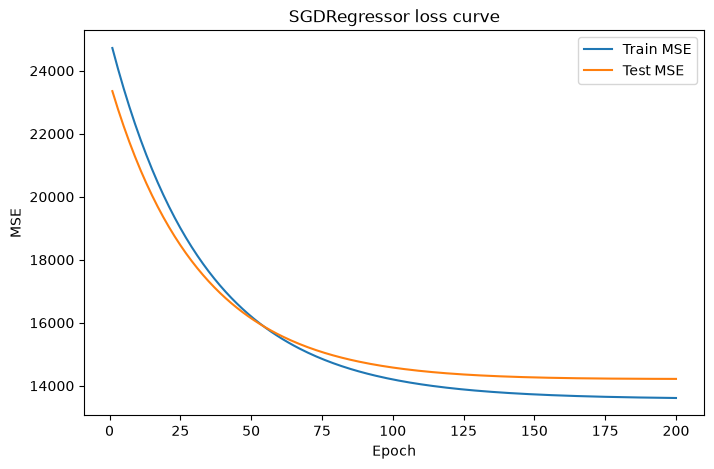

Final epoch -> train: 13612.5 | test: 14218.7


In [25]:
loss_curve_model = SGDRegressor(learning_rate="constant",eta0=best_sgd["learning_rate"], alpha=best_sgd["alpha"], random_state=42)

train_losses, test_losses = [], []
for epoch in range(int(best_sgd["epochs"])):
    loss_curve_model.partial_fit(X_train_scaled, y_train)  # one pass over the training set
    train_losses.append(mean_squared_error(y_train, loss_curve_model.predict(X_train_scaled)))
    test_losses.append(mean_squared_error(y_test, loss_curve_model.predict(X_test_scaled)))

epoch_numbers = range(1, len(train_losses) +1)

plt.figure(figsize=(8, 5))
plt.plot(epoch_numbers, train_losses, label="Train MSE")
plt.plot(epoch_numbers, test_losses, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("SGDRegressor loss curve")
plt.legend()
plt.show()

print("Final epoch -> train:", round(train_losses[-1], 1), "| test:", round(test_losses[-1], 1))

The loss curve shows train and test MSE for SGDRegressor over 200 epochs, using the tuned settings (learning rate 1e-5, alpha = 1). Both curves fall quickly at first and then level off, so training has converged and more epochs would not help. At the final epoch, train MSE is 13,612 and test MSE is 14,219, a small gap of about 600 that shows little overfitting. Test MSE is only about 2% below the predict-the-mean baseline (14,510), which confirms the features carry limited linear signal.

### 6.2 Scatter Plot, before: the most correlated feature against the target

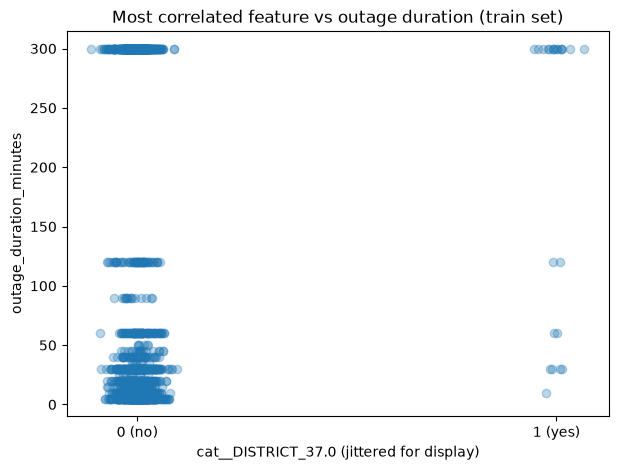

Training households where it is 1: 24 of 1425


In [26]:
feature_position = list(encoded_feature_names).index(most_correlated_feature)
feature_values = X_train_encoded[:, [feature_position]]  # unscaled 0/1 values, train set

random_generator = np.random.default_rng(42)
jittered_values = feature_values.ravel() + random_generator.normal(0, 0.03, len(feature_values))

plt.figure(figsize=(7, 5))
plt.scatter(jittered_values, y_train, alpha=0.3)
plt.xticks([0, 1], ["0 (no)", "1 (yes)"])
plt.xlabel(f"{most_correlated_feature} (jittered for display)")
plt.ylabel(target_col)
plt.title("Most correlated feature vs outage duration (train set)")
plt.show()

print("Training households where it is 1:", int(feature_values.sum()), "of", len(feature_values))

This scatter plots the feature most correlated with outage duration, a district 37 indicator, against the target. Outages in district 37 cluster at the top of the range (many at the 300-minute cap), while the other districts spread from 5 to 300 minutes with most under 60. I kept the feature because it is the strongest single signal I found, but only 24 of the 1,425 training households (about 1.7%) are in district 37, so I treat it as weak evidence.

### 6.3 Scatter plot, after: with the fitted regression line.

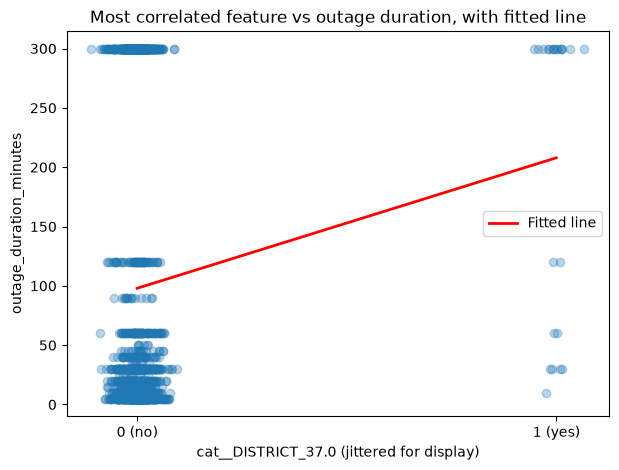

Intercept: 97.9 | Slope: 110.0


In [27]:
one_feature_model = LinearRegression().fit(feature_values, y_train)  # for this plot only

line_x = np.array([[0], [1]])
plt.figure(figsize=(7, 5))
plt.scatter(jittered_values, y_train, alpha=0.3)
plt.plot(line_x, one_feature_model.predict(line_x), color="red", linewidth=2, label="Fitted line")
plt.xticks([0, 1], ["0 (no)", "1 (yes)"])
plt.xlabel(f"{most_correlated_feature} (jittered for display)")
plt.ylabel(target_col)
plt.title("Most correlated feature vs outage duration, with fitted line")
plt.legend()
plt.show()

print("Intercept:", round(one_feature_model.intercept_, 1), "| Slope:", round(one_feature_model.coef_[0], 1))

The one-feature linear regression predicts about 98 minutes for households outside district 37 and about 208 for district 37, a difference of 110 minutes. With a 0/1 feature the line simply joins the two group averages, and it misses the wide spread around each. Even the strongest single feature explains little of the variation, which matches the near-baseline MSE of the full models

## 7. Save the best model
The fitted preprocessing (imputing, one-hot encoding, scaling) and the best model are joined into one scikit-learn `Pipeline`, so the API can pass in raw values. It is saved with joblib straight into the API folder, together with the training data that `/retrain` uses..

In [28]:
# Join the fitted preprocessing with the best model, so the API can take raw inputs
best_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("scaler", scaler),
    ("model", final_models[best_model_name]),
])
print("Best model:", best_model_name)
print("Pipeline test MSE:", round(mean_squared_error(y_test, best_pipeline.predict(X_test)), 1))

joblib.dump(best_pipeline, api_folder / "best_model.pkl")

# The API's /retrain endpoint refits on this data plus the uploaded rows
model_data = X.copy()
model_data[target_col] = y
model_data.to_csv(api_folder / "model_data.csv", index=False)

print("Saved best_model.pkl and model_data.csv to", api_folder.resolve())

Best model: Random Forest
Pipeline test MSE: 13521.8
Saved best_model.pkl and model_data.csv to D:\Dev\schProjects\MathForML\linear_regression_model\summative\API


### 7.1 Predict one row of the test set with the saved model

In [29]:
def predict_one_row(row_number, model_file=api_folder / "best_model.pkl"):
    """Load the saved model and predict outage duration for one row of the test set."""
    saved_model = joblib.load(model_file)
    one_row = X_test.iloc[[row_number]]  # double brackets keep it a 1-row table
    return saved_model.predict(one_row)[0]


prediction = predict_one_row(0)
print("Predicted:", round(prediction, 1), "minutes | Actual:", y_test.iloc[0], "minutes")

Predicted: 91.0 minutes | Actual: 25.0 minutes


## 8. Conculsion

## 8. Conclusion
Random Forest has the lowest test MSE (13,521.8, an average error of about 116 minutes), about 7% below the predict-the-mean baseline (14,510.1, about 120 minutes). Tuned SGD (14,217) beats the baseline by only about 2%, and closed-form Linear Regression (15,055) is slightly worse than the baseline, because without regularization it fits the 67 one-hot columns too closely. The default Decision Tree overfits badly (train 368, test 21,925). Random Forest also overfits (train 2,262 vs test 13,522), but averaging many trees cancels much of the error, and it captures non-linear effects such as C006's, so it generalizes best.

Overall the error is high for this use case: the survey variables explain only about 7% of the variation in outage duration. To reduce it further I would add stronger predictors (for example feeder or substation records, local weather, or the grid operator's own outage logs), tune the Random Forest's depth and leaf size, and collect more households in under-represented districts.